## k-means clustering algorithm to cluster data into multiple groups 

## Load and Explore the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = pd.read_csv("store_customers.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1000,M,39.0,59.9,58.0
1,1001,M,34.0,48.4,37.0
2,1002,F,40.0,70.5,26.0
3,1003,F,47.0,81.1,30.0
4,1004,F,33.0,42.1,58.0


In [4]:
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

Number of rows: 1000
Number of columns: 5


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              1000 non-null   int64  
 1   Gender                  997 non-null    object 
 2   Age                     994 non-null    float64
 3   Annual Income (k$)      996 non-null    float64
 4   Spending Score (1-100)  994 non-null    float64
dtypes: float64(3), int64(1), object(1)
memory usage: 39.2+ KB


In [6]:
print("Missing values in each column:")
print(data.isnull().sum())

Missing values in each column:
CustomerID                0
Gender                    3
Age                       6
Annual Income (k$)        4
Spending Score (1-100)    6
dtype: int64


In [7]:
data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,1000.000000,994.000000,996.000000,994.000000
mean,1499.500000,38.935614,57.149096,42.645875
std,288.819436,13.399880,28.628506,20.101589
min,1000.000000,18.000000,15.000000,1.000000
25%,1249.750000,30.000000,34.975000,31.000000
50%,1499.500000,36.000000,49.000000,47.000000
75%,1749.250000,44.000000,79.400000,57.000000
max,1999.000000,80.000000,144.100000,92.000000


## Select Features for Clustering

In [8]:
X = data[
    ["Annual Income (k$)", "Spending Score (1-100)"]
].copy()

print("Selected features:")
print(X.head())

Selected features:
   Annual Income (k$)  Spending Score (1-100)
0                59.9                    58.0
1                48.4                    37.0
2                70.5                    26.0
3                81.1                    30.0
4                42.1                    58.0


In [10]:
# Check missing values before handling them
print("Missing values before handling:")
print(X.isnull().sum())

# Fill missing values with the median
X = X.copy()

X["Annual Income (k$)"] = X["Annual Income (k$)"].fillna(
    X["Annual Income (k$)"].median()
)

X["Spending Score (1-100)"] = X["Spending Score (1-100)"].fillna(
    X["Spending Score (1-100)"].median()
)

# Check missing values after handling
print("\nMissing values after handling:")
print(X.isnull().sum())

Missing values before handling:
Annual Income (k$)        4
Spending Score (1-100)    6
dtype: int64

Missing values after handling:
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


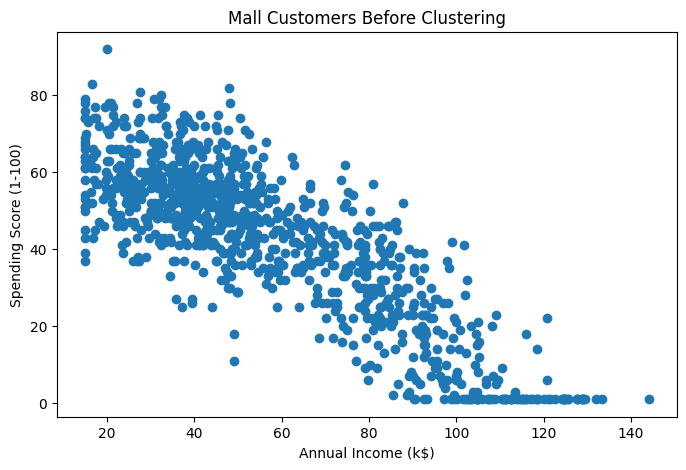

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"]
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Mall Customers Before Clustering")

plt.show()

## Feature Scaling

In [12]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")
print("First five scaled records:")
print(X_scaled[:5])

Feature scaling completed!
First five scaled records:
[[ 0.09745644  0.76510194]
 [-0.3051838  -0.28311966]
 [ 0.46858571 -0.83218813]
 [ 0.83971497 -0.63252687]
 [-0.52576062  0.76510194]]


## Find the Optimal Number of Clusters

In [13]:
##Calculate WCSS for different K values 
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

print("WCSS values:")
print(wcss)

WCSS values:
[2000.0000000000002, 648.3854502238978, 394.52214904776713, 289.4145569736987, 238.9084352423685, 202.7585589125846, 167.26750911281653, 148.93022943067277, 133.48266880043272, 120.80948114237906]


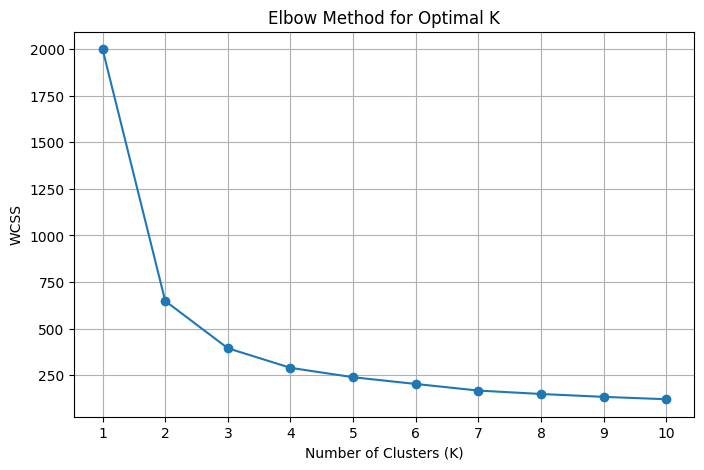

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal K")

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

## Apply K-Means Clustering

In [15]:
## create the k-means mmodel 
kmeans = KMeans(
    n_clusters=5,
    init="k-means++",
    random_state=42,
    n_init=10
)

print("K-Means model created successfully!")

K-Means model created successfully!


In [16]:
## Train 
kmeans.fit(X_scaled)

print("K-Means clustering completed!")

K-Means clustering completed!


In [19]:
## get cluster label
labels = kmeans.labels_
print("Cluster labels:")
print(labels)

Cluster labels:
[0 0 3 3 4 2 3 3 0 4 4 2 0 2 2 4 4 0 4 2 3 4 4 4 2 0 4 0 4 0 4 3 4 2 0 4 0
 4 2 2 3 0 4 4 2 4 2 0 0 2 4 4 4 0 3 3 4 4 4 3 2 4 2 2 0 3 4 3 4 4 0 1 2 3
 4 0 0 0 2 4 0 0 3 4 4 4 3 0 4 0 0 0 4 2 4 2 0 2 4 4 2 2 4 0 0 4 1 0 4 2 2
 0 0 1 4 0 4 4 3 3 1 2 3 4 3 1 2 2 0 2 4 0 4 0 4 3 4 0 0 4 0 3 2 3 2 0 4 0
 0 4 0 0 2 4 0 4 3 0 2 3 2 3 3 4 3 0 3 3 4 4 4 4 0 0 4 3 4 3 2 1 0 4 4 4 2
 3 0 3 4 2 0 3 0 2 3 0 2 2 0 4 2 2 3 3 2 4 4 2 4 1 3 3 0 0 0 3 4 4 0 2 1 4
 0 2 4 3 4 4 4 0 2 4 4 2 3 0 4 2 4 0 0 4 0 3 4 0 2 2 0 0 4 3 3 3 2 4 3 2 2
 3 2 2 4 2 0 4 3 4 2 4 3 4 3 2 0 0 0 4 0 4 0 3 3 4 3 2 0 0 0 0 2 4 0 3 0 4
 3 0 3 0 4 4 0 3 4 0 3 4 0 4 4 3 0 0 3 0 0 0 0 0 4 3 4 1 4 2 3 0 0 0 4 4 0
 2 3 4 2 4 0 2 4 4 0 4 2 0 4 4 4 2 0 3 0 4 4 4 4 2 4 2 0 1 0 4 3 0 4 4 0 0
 0 0 3 3 3 0 3 0 3 4 2 2 2 2 4 0 0 3 3 0 0 0 4 3 3 0 2 3 0 0 4 4 4 0 0 3 4
 4 4 0 0 4 4 3 4 4 3 0 0 0 3 1 4 0 0 3 4 0 3 2 4 4 0 0 3 0 3 4 4 4 0 4 4 0
 4 0 0 4 4 4 4 0 2 0 4 2 4 4 4 4 3 4 4 4 0 0 3 1 0 4 0 2 4 3 3 2 3 4 1 3 0
 0 4 0 4 

In [20]:
## Add cluster labels to dataset 
data["Cluster"] = labels
data.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1000,M,39.0,59.9,58.0,0
1,1001,M,34.0,48.4,37.0,0
2,1002,F,40.0,70.5,26.0,3
3,1003,F,47.0,81.1,30.0,3
4,1004,F,33.0,42.1,58.0,4


In [21]:
print("Number of customers in each cluster:")
print(data["Cluster"].value_counts().sort_index())

Number of customers in each cluster:
Cluster
0    239
1    136
2    151
3    176
4    298
Name: count, dtype: int64


## Visualize the Clusters

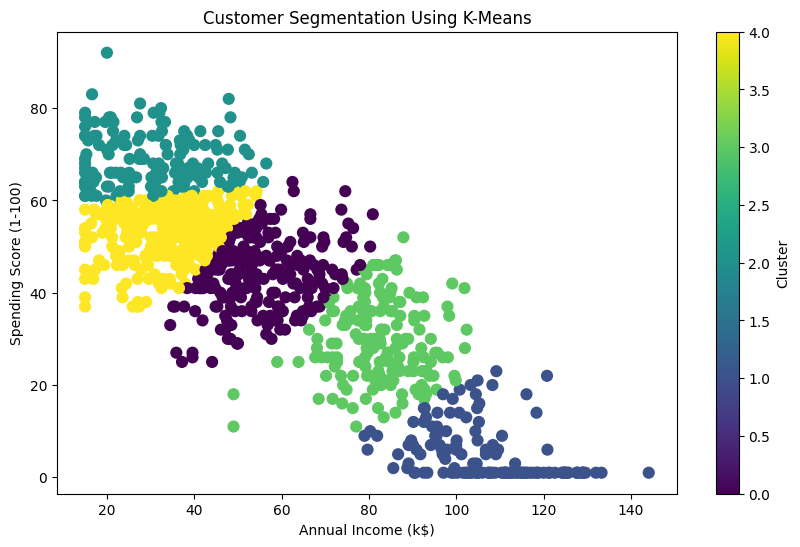

In [22]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"],
    c=labels,
    cmap="viridis",
    s=60
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segmentation Using K-Means")
plt.colorbar(label="Cluster")
plt.show()

In [23]:
## display cluster centroid 
centroids_scaled = kmeans.cluster_centers_

centroids_original = scaler.inverse_transform(
    centroids_scaled
)

centroids_df = pd.DataFrame(
    centroids_original,
    columns=X.columns
)

print("Cluster Centroids:")
print(centroids_df.round(2))

Cluster Centroids:
   Annual Income (k$)  Spending Score (1-100)
0               55.25                   43.93
1              106.91                    5.26
2               31.03                   68.85
3               82.45                   29.80
4               34.06                   53.12


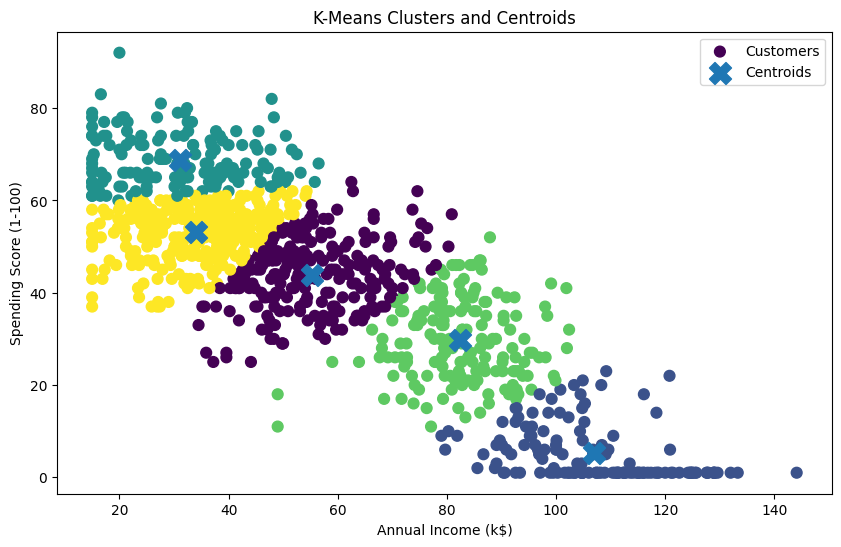

In [24]:
## plot the cluster with centroid 
plt.figure(figsize=(10, 6))

plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"],
    c=labels,
    cmap="viridis",
    s=60,
    label="Customers"
)

plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Clusters and Centroids")

plt.legend()
plt.show()

## Evaluate the Clusters

In [25]:
## Calculate the Silhouette Score 
score = silhouette_score(X_scaled, labels)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.3658


In [26]:
## Compare Silhouette Scores for different K values 
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    cluster_labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        cluster_labels
    )

    silhouette_scores.append(score)

print("Silhouette scores for K = 2 to 10:")

for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K = {k}: {score:.4f}")

Silhouette scores for K = 2 to 10:
K = 2: 0.5800
K = 3: 0.4735
K = 4: 0.3927
K = 5: 0.3658
K = 6: 0.3491
K = 7: 0.3719
K = 8: 0.3589
K = 9: 0.3531
K = 10: 0.3478


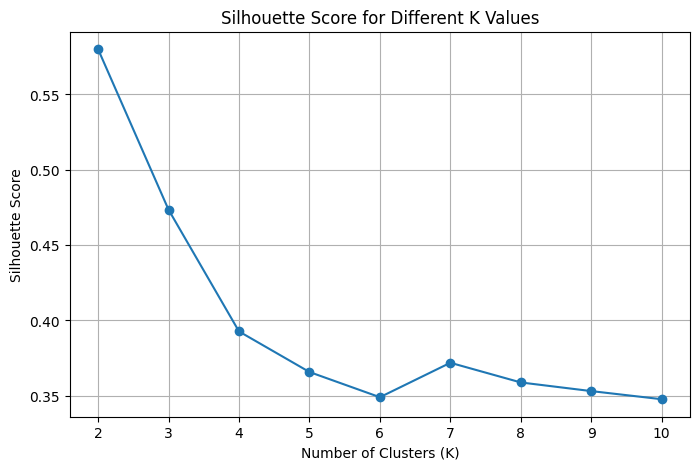

In [27]:
## PLOT 
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

## Understand the Customer Groups

In [28]:
cluster_summary = data.groupby("Cluster")[
    ["Annual Income (k$)", "Spending Score (1-100)"]
].mean().round(2)

print("Average characteristics of each cluster:")
print(cluster_summary)

Average characteristics of each cluster:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.34                   43.92
1                    106.91                    5.26
2                     30.79                   68.85
3                     82.86                   29.61
4                     34.06                   53.21


In [30]:
## Display the final dataset
data.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1000,M,39.0,59.9,58.0,0
1,1001,M,34.0,48.4,37.0,0
2,1002,F,40.0,70.5,26.0,3
3,1003,F,47.0,81.1,30.0,3
4,1004,F,33.0,42.1,58.0,4
5,1005,M,33.0,36.7,73.0,2
6,1006,F,48.0,90.4,34.0,3
7,1007,F,41.0,74.8,35.0,3
8,1008,F,31.0,42.3,43.0,0
9,1009,M,39.0,48.6,61.0,4


## Conclusion:
K-Means Clustering was implemented successfully on the Mall Customer Segmentation dataset. Annual Income and Spending Score were selected as features and standardized before applying the algorithm. The Elbow Method was used to help select the number of clusters, and K-Means assigned customers to groups based on their similarity. The resulting clusters and centroids were visualized using scatter plots, and the Silhouette Score was calculated to evaluate cluster separation. The experiment demonstrated how unsupervised learning can be used for customer segmentation.
